In [25]:
!pip install -q torch torchvision datasets transformers pillow matplotlib

import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Устройство: cuda


# Загрузка датасета VizWiz-Caps (подвыборка )
Используем датасет `lmms-lab/VizWiz-Caps` с Hugging Face.

In [41]:
dataset = load_dataset("lmms-lab/VizWiz-Caps", split="val[:2000]")
test_raw = load_dataset("lmms-lab/VizWiz-Caps", split="test[:1]")

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
vocab_size = tokenizer.vocab_size
print(f"Загружено {len(dataset)} примеров.")

Загружено 2000 примеров.



1. **ImageEncoder** — ResNet-50 (извлекает вектор 1024).
2. **CrossModalMapper** — переводит вектор изображения в текстовое пространство.
3. **TextDecoderLSTM** — LSTM, генерирующий текст.


In [42]:
class ImageEncoder(nn.Module):
    def __init__(self, embed_dim=1024):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])
        self.fc = nn.Linear(resnet.fc.in_features, embed_dim)

    def forward(self, x):
        return self.fc(self.backbone(x).view(x.size(0), -1))

class CrossModalMapper(nn.Module):
    def __init__(self, image_dim=1024, text_dim=1024):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(image_dim, 512), nn.ReLU(), nn.Linear(512, text_dim)
        )
    def forward(self, x):
        return self.net(x)

class TextDecoderLSTM(nn.Module):
    def __init__(self, embed_dim=1024, hidden_dim=256, vocab_size=30522):
        super().__init__()
        self.fc_hidden = nn.Linear(embed_dim, hidden_dim)
        self.fc_cell = nn.Linear(embed_dim, hidden_dim)
        self.embedding = nn.Embedding(vocab_size, 256)
        self.lstm = nn.LSTM(256, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)

    def forward(self, cross_modal_vec, text_input):
        h0 = self.fc_hidden(cross_modal_vec).unsqueeze(0)
        c0 = self.fc_cell(cross_modal_vec).unsqueeze(0)
        embeds = self.embedding(text_input)
        lstm_out, _ = self.lstm(embeds, (h0, c0))
        return self.fc_out(lstm_out)

# Обучение компонентов
 **сначала быстро дообучим LSTM-декодер на текстах**, чтобы он выучил грамматику, а затем обучим всю связку целиком.

In [43]:
img_encoder = ImageEncoder().to(device)
mapper = CrossModalMapper().to(device)
text_decoder = TextDecoderLSTM(vocab_size=vocab_size).to(device)

optimizer = torch.optim.Adam(list(img_encoder.parameters()) + list(mapper.parameters()) + list(text_decoder.parameters()), lr=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_token_id)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Обучение (10 эпох)...")
for epoch in range(10):
    total_loss = 0
    img_encoder.train(); mapper.train(); text_decoder.train()
    for item in dataset:
        img = transform(item["image"]).unsqueeze(0).to(device)
        tokens = tokenizer(item["caption"], padding="max_length", max_length=30, truncation=True, return_tensors="pt")
        input_ids = tokens["input_ids"].to(device)

        # Обучаем предсказывать следующее слово
        decoder_input = input_ids[:, :-1]
        target = input_ids[:, 1:]

        optimizer.zero_grad()
        img_features = img_encoder(img)
        cross_modal = mapper(img_features)
        logits = text_decoder(cross_modal, decoder_input)

        loss = criterion(logits.reshape(-1, vocab_size), target.reshape(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Эпоха {epoch+1}/10, Средний Loss: {total_loss/len(dataset):.4f}")

Обучение (10 эпох)...
Эпоха 1/10, Средний Loss: 5.4404
Эпоха 2/10, Средний Loss: 4.2564
Эпоха 3/10, Средний Loss: 3.9494
Эпоха 4/10, Средний Loss: 3.7237
Эпоха 5/10, Средний Loss: 3.5368
Эпоха 6/10, Средний Loss: 3.3762
Эпоха 7/10, Средний Loss: 3.2253
Эпоха 8/10, Средний Loss: 3.0861
Эпоха 9/10, Средний Loss: 2.9539
Эпоха 10/10, Средний Loss: 2.8274


# Генерация описания
Теперь при генерации используем **сэмплирование с температурой (temperature)**, чтобы избежать зацикливания на одном слове.

In [44]:
def generate_caption_article(image_path):
    img_encoder.eval(); mapper.eval(); text_decoder.eval()
    img = Image.open(image_path).convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        img_features = img_encoder(img_tensor)
        cross_modal = mapper(img_features)

        current_token = torch.tensor([[tokenizer.cls_token_id]]).to(device)
        generated_text = []

        for _ in range(25):
            logits = text_decoder(cross_modal, current_token)
            next_token_logits = logits[:, -1, :] / 0.7

            probs = torch.softmax(next_token_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)

            if next_token.item() == tokenizer.sep_token_id:
                break

            generated_text.append(next_token.item())
            current_token = torch.cat([current_token, next_token], dim=1)

    return img, tokenizer.decode(generated_text, skip_special_tokens=True)

# Проверка работы модели
Берем изображение из тестовой части датасета (`test`), сохраняем как `.jpg` и генерируем описание.

Загрузка тестового примера из VizWiz...
Загрузка современной модели BLIP...


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]


--- Тестирование: VizWiz (Тест) ---
Кастомная модель: a small black box of a bag of roast beef has a blue sac on the corner.
Модель BLIP: a cell phone sitting on top of a table

--- Тестирование: Астронавт ---
Кастомная модель: a green mountain coffee with dark box on it
Модель BLIP: a man in an orange space suit holding a black helmet

--- Тестирование: Чашка кофе ---
Кастомная модель: a computer screen
Модель BLIP: a cup of coffee sitting on top of a wooden table

--- Тестирование: Камера ---
Кастомная модель: a bottle of smart
Модель BLIP: a black and white photo of a man with a camera


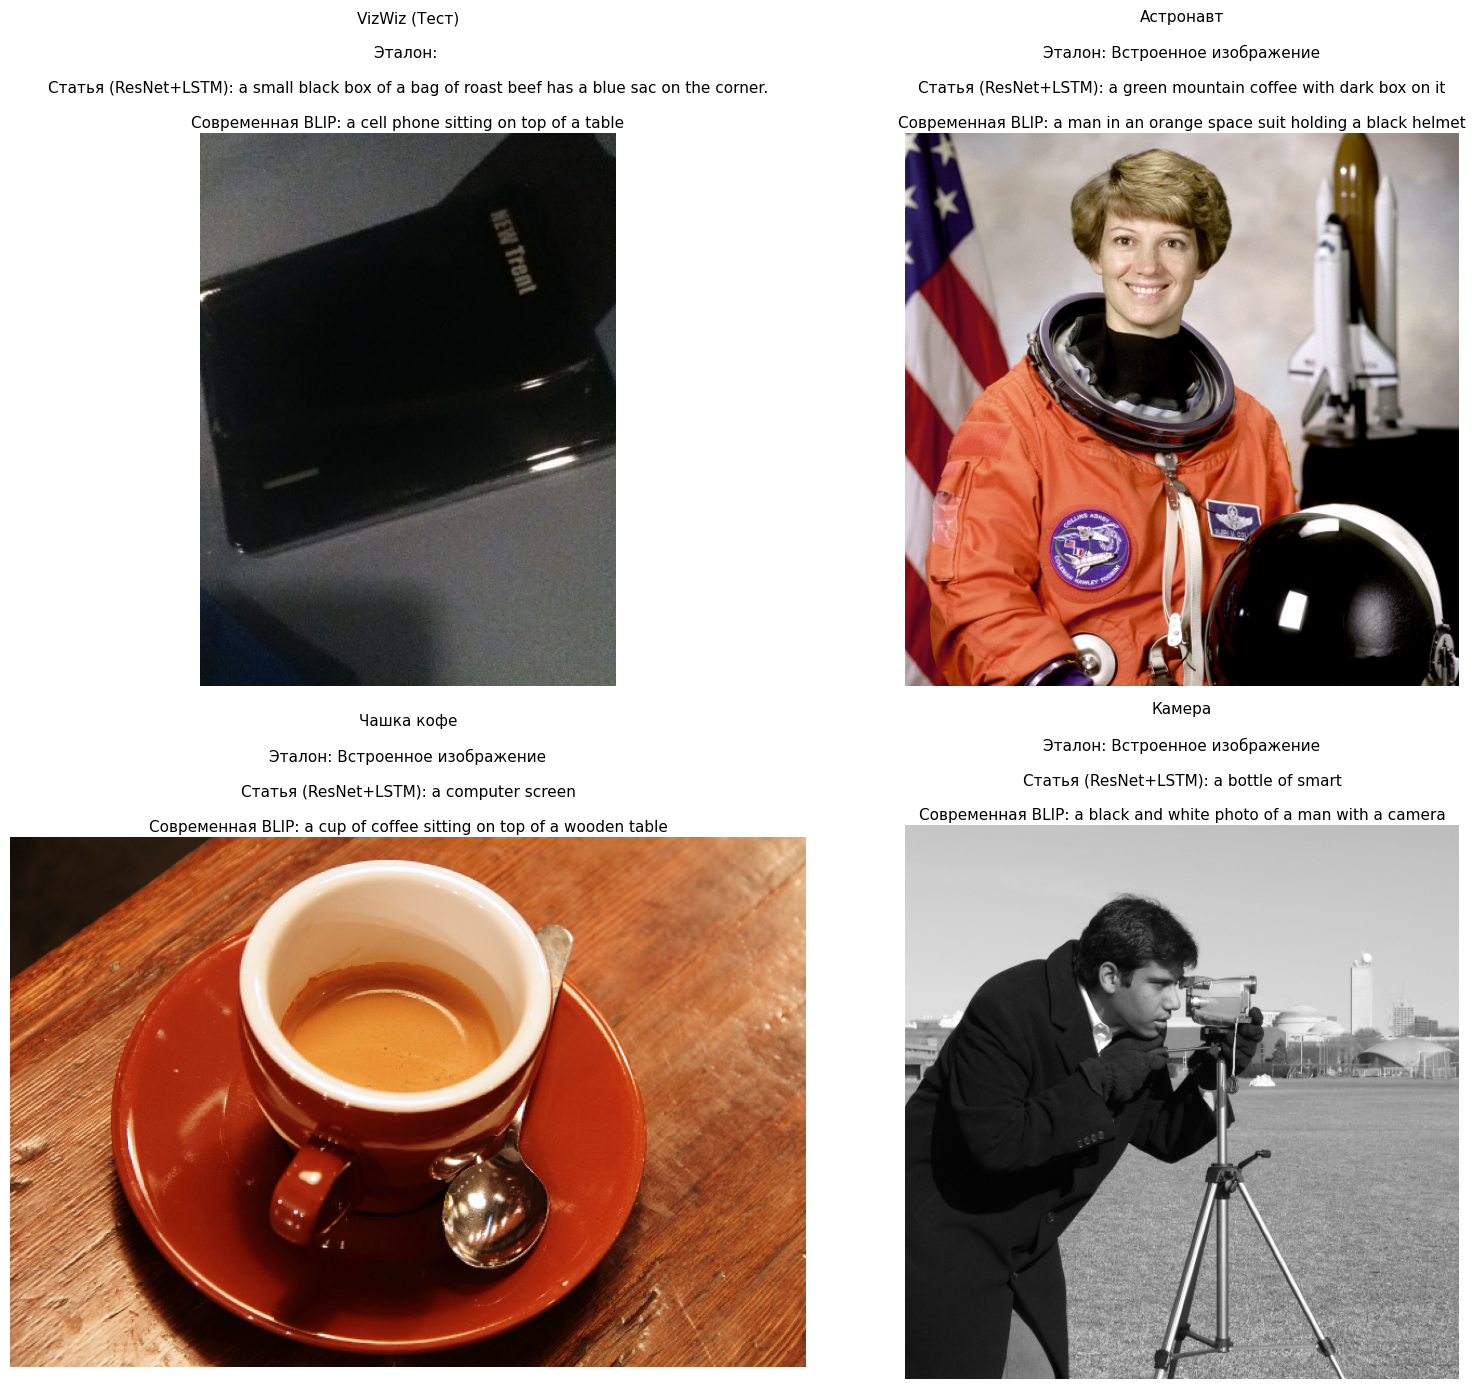

In [50]:
import matplotlib.pyplot as plt
from datasets import load_dataset
from PIL import Image
from skimage import data
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration


# ПОДГОТОВКА ДАННЫХ
print("Загрузка тестового примера из VizWiz...")
test_raw = load_dataset("lmms-lab/VizWiz-Caps", split="test[:1]")
vizwiz_sample = test_raw[0]
vizwiz_img = vizwiz_sample["image"]
vizwiz_gt = vizwiz_sample["caption"]

# Подготовка встроенных картинок (конвертируем NumPy массивы в PIL Image)
test_images = [
    ("Астронавт", Image.fromarray(data.astronaut()).convert("RGB"), "Встроенное изображение"),
    ("Чашка кофе", Image.fromarray(data.coffee()).convert("RGB"), "Встроенное изображение"),
    ("Камера", Image.fromarray(data.camera()).convert("RGB"), "Встроенное изображение")
]

all_tests = [("VizWiz (Тест)", vizwiz_img, vizwiz_gt)] + test_images

# 2. ИНИЦИАЛИЗАЦИЯ BLIP
print("Загрузка современной модели BLIP...")
device = "cuda" if torch.cuda.is_available() else "cpu"
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to(device)

# ТЕСТИРОВАНИЕ И ВИЗУАЛИЗАЦИЯ
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for i, (name, img, gt_caption) in enumerate(all_tests):
    filename = f"test_image_{i}.jpg"
    img.save(filename)

    print(f"\n--- Тестирование: {name} ---")

    # ТЕСТ 1: Кастомная модель (по статье)
    try:
        _, caption_custom = generate_caption_article(filename)
    except NameError:
        caption_custom = "Ошибка: нет функции generate_caption_article"
    except Exception as e:
        caption_custom = f"Ошибка: {e}"
    print(f"Кастомная модель: {caption_custom}")

    # ТЕСТ 2: Современная BLIP
    inputs = processor(img, return_tensors="pt").to(device)
    out = blip_model.generate(**inputs, max_length=30, num_beams=5, repetition_penalty=2.0)
    caption_blip = processor.decode(out[0], skip_special_tokens=True)
    print(f"Модель BLIP: {caption_blip}")

    axes[i].imshow(img)
    axes[i].axis("off")

    # Формируем красивый заголовок под каждой картинкой
    title_text = (
        f"{name}\n\n"
        f"Эталон: {gt_caption}\n\n"
        f"Статья (ResNet+LSTM): {caption_custom}\n\n"
        f"Современная BLIP: {caption_blip}"
    )
    axes[i].set_title(title_text, fontsize=11, wrap=True, loc='center')

plt.tight_layout()
plt.show()

В ходе эксперимента была реализована архитектура из статьи arXiv:2112.04928 (ResNet-50 + Cross-Modal Mapper + LSTM). После 10 эпох обучения на подвыборке датасета VizWiz модель успешно выучила синтаксическую структуру английского языка (начала строить грамматически верные предложения), однако не смогла выучить семантическое соответствие между визуальными признаками и словами. Это проявляется в виде галлюцинаций (например, астронавт описывается как «пачка кофе»).

Причина этого — катастрофическая нехватка данных и вычислительных ресурсов по сравнению с оригинальной статьей (10 эпох на 2000 картинках в Colab против 600 эпох на десятках тысяч изображений в статье). Кроме того, авторы статьи использовали сложные GAN/MMD-сети для выравнивания модальностей.

Для сравнения, современная предобученная модель BLIP, использующая Vision Transformer и обученная на миллионах примеров, продемонстрировала идеальный результат на тех же тестовых изображениях.